# KLASIFIKASI BINER DENGAN SVM (SUPPORT VECTOR MACHINE)

---

**Author**: Hanna MA

PEMODELAN DAN PEMBELAJARAN MESIN

</br>

**Referensi**: </br>
- [Kaggle | SVM from Scratch](https://www.kaggle.com/code/fareselmenshawii/svm-from-scratch)
- [Github | MWalega/ml_algos_python/SVM.py](https://github.com/MWalega/ml_algos_python/blob/master/SVM.py)
- [Github | akash18tripathi/SVM-from-scratch-Constraints-analysis/SVM.ipynb](https://github.com/akash18tripathi/SVM-from-scratch-Constraints-analysis/blob/main/SVM.ipynb)
- [Youtube | Siddhardhan: Support Vector Machine Classifier from Scratch](https://youtube.com/playlist?list=PLfFghEzKVmjvzS4DILijsdQk27Ew7xIPu&feature=shar)

# 1. KONSEP UMUM

## 🟡 **KONSEP KLASIFIKASI BINER**

Klasifikasi biner dalam pembelajaran mesin merupakan algoritma *supervised learning* yang mengategorisasikan data pada dua kelas berbeda. Beberapa metode yang biasa diterapkan dalam proses klasifikasi biner dapat berupa:

1. K-Nearest Neighbors (KNN)
2. Decision trees
3. Random forest
4. **Support Vector Machine** (SVM), dll.

Metrik evaluasi paling umum dalam masalah klasifikasi biner adalah **akurasi**.

## 🟡 **KONSEP SVM**

*Support Vector Machine* (SVM) merupakan algoritma *supervised machine learning* yang mengklasifikasikan data dengan mencari garis optimal yang merupakan jarak terjauh antar klasifikasi data pada ruang dimensinya.

**Kompoenen penting** dalam SVM meliputi:
1. **Hyperplane**: garis atau bidang yang memisahkan *data-points* dalam dua kelas.
2. **Support vector**: *data-points* yang berada dekat dengan *hyperplane*.

### **MODEL MATEMATIS KLASIFIKASI SVM**

**(1) Persamaan *Linear Classifiers***

Klasifikasi SVM ditentukan oleh sebuah garis linier--hyperplane yang membagai dua kelas (target) dari dataset. Bentuk *linear classifier* dituliskan sebagai berikut.

</br>

\begin{align}
f(x) &= w^Tx + b &&\text{... (1)} \\
f(x) &= w^Tx &&\text{... (2)}
\end{align}

</br>

dimana: </br>
* $w$ adalah vektor bobot (*weight*)
* $b$ adalah parameter bias

Perbedaan kedua persamaan $(1)$ dan $(2)$ dibedakan berdasarkan posisi *hyperplane* yang merentang pada dimensi model SVM terkait.

</br>

**(2) Optimasi Masalah SVM**

</br>

![SVM Marigin](https://drive.google.com/uc?export=view&id=12Rrf38tG8HlwFBmrYypSAr7idGYVMmF1)

</br>

Berdasarkan gambar tersebut (lampiran gambar diperlukan), kalkulasi kedua persamaan margin sebagai berikut.

\begin{array}{rcl}
w^Tx_1 + b &= &1 \\
w^Tx_2 + b &= &-1 \\
\hline
w^T(x_1 - x_2) &= &2
\end{array}

</br>

Berdasarkan hasil eliminiasi kedua persamaan sebelumnya, dapat diproses lebih lanjut menjadi:

\begin{align}
w^T(x_1 - x_2) &= 2 &&\text{... (3.a)} \\
\frac{w^T}{||w||} (x_1-x_2) &= \frac{2}{||w||} \\
(1)(x_1-x_2) &= \frac{2}{||w||} \\
(x_1-x_2) &= \frac{2}{||w||} &&\text{... (3.b)}
\end{align}

</br>

Sehingga, dapat dituliskan kasus maksimasi nilai margin, yaitu:

\begin{align}
\text{max} \quad &\frac{2}{||w||} &&\text{... (4)}\\\\
\text{s.t} \quad &w^Tx_i + b \leq -1; \quad &y_i = -1 \\
&w^Tx_i + b \geq 1; \quad &y_i = +1
\end{align}

### **SVM DENGAN GRADIENT DESCENT**

**Loss Function**

*Loss function* total untuk SVM dengan **Hinge Loss**, dituliskan sebagai:

\begin{align}
L= \max(0, 1 - \underbrace{y_i (w^Tx_i + b)}_{\text{predicted transform}}) &&\text{... (5)}
\end{align}

di mana:
- $y_i$ adalah label kelas untuk contoh ke-$i$ ($y_i \in \{-1, 1\}$)
- $0$ dan $1$ merupakan classification value

    **0** - *correct classification*  </br>
    **1** - *wrong classificaiton*

</br>

**Parameter Gradient Descent**

Parameter diperbarui untuk meminimalkan *Loss Function* untuk nilai bobot ($w$) dan bias ($b$):

\begin{align}
w_2 &= w_1 - \eta \frac{\partial J}{\partial w} &&\text{... (6.a)}\\
b_2 &= b_1 - \eta \frac{\partial J}{\partial b} &&\text{... (6.b)}
\end{align}

dimana: </br>
- $\eta$ adalah *learning rate*
- $J$ adalah *cost function*

</br>

**Persamaan Gradient Descent untuk SVM**

Persamaan gradien dari *cost function* terhadap nilai bobot dan bias, dituliskan sebagai berikut:

- Jika $y_i (w\cdot x_i + b) \geq 1$, berlaku:
\begin{align}
\frac{\partial J}{\partial w} &= 2\lambda w \\
\frac{\partial J}{\partial b} &= 0
\end{align}

</br>

- Jika $y_i (w \cdot x_i + b) < 1$, berlaku:
\begin{align}
\frac{\partial J}{\partial w} &= 2\lambda w - y_i x_i \\
\frac{\partial J}{\partial b} &= -y_i
\end{align}

</br>

Proses ini diulangi hingga konvergen, yaitu saat perubahan pembaruan parameter kecil atau fungsi kehilangan mencapai nilai minimum.

# 2. IMPLEMENTASI


### **TENTANG DATASET**

**Electricity Dataset (Elec2)** dikumpulkan dari Pasar Listrik New South Wales (NSW), Australia. Dataset ini digunakan untuk mempelajari perubahan harga listrik dan merupakan masalah binary classification

Sumber: [Max Halford](https://maxhalford.github.io/files/datasets/electricity.zip)

**Dataset Summary:**
- **45.312** sampel observasi
- 8 fitur + 1 target
- interval update harga tiap 5 menit

| Kolom | Deskripsi |
| --- | ---|
| `date` | info tanggal dalam format numerik |
| `day` | hari dalam seminggu |
| `period` | periode pengamatan dalam sehari |
| `nswprice` | harga listrik NSW |
| `nswdemand` | permintaan listrik NSW |
| `vicprice` | harga listrik Victoria |
| `vicdemand` | permintaan listrik Victoria |
| `transfer` | transfer listrik antarwilayah |
| `class` | target harga naik atau turun |

Target `class` memiliki dua kategori:
- `UP`: harga listrik naik
- `DOWN`: harga listrik turun

### **Import Library**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from plotly.subplots import make_subplots
# import plotly.graph_objects as go
# import plotly.express as px


### **Data set**

In [ ]:
URL = "https://maxhalford.github.io/files/datasets/electricity.zip"

df = pd.read_csv(URL, compression="zip")
df


,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,class
0,0.0000,2,0.000000,0.056443,0.439155,0.003467,0.422915,0.414912,UP
1,0.0000,2,0.021277,0.051699,0.415055,0.003467,0.422915,0.414912,UP
2,0.0000,2,0.042553,0.051489,0.385004,0.003467,0.422915,0.414912,UP
3,0.0000,2,0.063830,0.045485,0.314639,0.003467,0.422915,0.414912,UP
4,0.0000,2,0.085106,0.042482,0.251116,0.003467,0.422915,0.414912,DOWN
...,...,...,...,...,...,...,...,...,...
45307,0.9158,7,0.914894,0.044224,0.340672,0.003033,0.255049,0.405263,DOWN
45308,0.9158,7,0.936170,0.044884,0.355549,0.003072,0.241326,0.420614,DOWN
45309,0.9158,7,0.957447,0.043593,0.340970,0.002983,0.247799,0.362281,DOWN
45310,0.9158,7,0.978723,0.066651,0.329366,0.004630,0.345417,0.206579,UP


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24548 entries, 0 to 24547
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       24548 non-null  float64
 1   day        24548 non-null  int64  
 2   period     24548 non-null  float64
 3   nswprice   24548 non-null  float64
 4   nswdemand  24548 non-null  float64
 5   vicprice   24548 non-null  float64
 6   vicdemand  24548 non-null  float64
 7   transfer   24548 non-null  float64
 8   class      24548 non-null  object 
dtypes: float64(7), int64(1), object(1)
memory usage: 1.7+ MB


In [ ]:
df.describe().iloc[1:]


,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer
mean,0.243478,3.998371,0.499757,0.062853,0.423331,0.003350,0.427190,0.449127
std,0.213091,2.000040,0.294782,0.027442,0.162778,0.000995,0.078812,0.099888
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.028742,0.000000
25%,0.017875,2.000000,0.234043,0.043413,0.304374,0.003467,0.422915,0.414912
50%,0.425202,4.000000,0.489362,0.056923,0.443767,0.003467,0.422915,0.414912
75%,0.443210,6.000000,0.744681,0.076618,0.534811,0.003467,0.422915,0.414912
max,0.461130,7.000000,1.000000,0.385013,0.935733,0.026011,0.790523,1.000000


###**Outlook Target**

Jumlah kelas (UP):  10471 dan (DOWN):  14077 



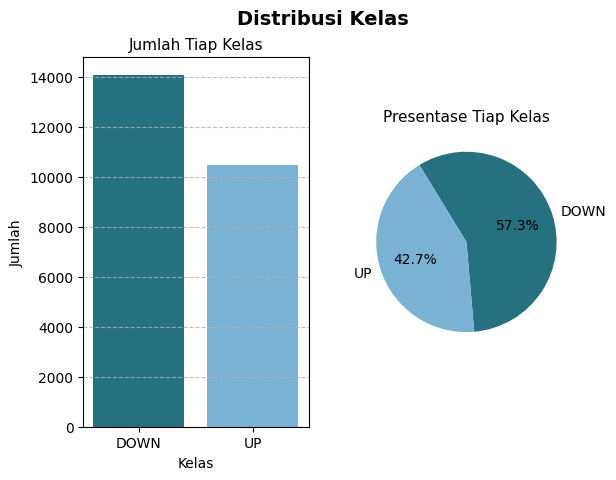

In [ ]:
class_count = df['class'].value_counts()
print('Jumlah kelas (UP): ', class_count['UP'],
      "dan (DOWN): ", class_count['DOWN'], '\n')

# plot bar chart
plt.subplot(1, 2, 1)
plt.bar(class_count.index, class_count.values,
        color = ['#257180', '#7AB2D3'])
plt.title('Jumlah Tiap Kelas', fontsize = 11)
plt.xlabel('Kelas')
plt.ylabel('Jumlah')
plt.grid(axis='y', linestyle = '--', alpha = 0.8)

# plot pie chart
plt.subplot(1, 2, 2)
plt.pie(class_count.values, labels = class_count.index,
        autopct = '%1.1f%%', colors = ['#257180', '#7AB2D3'], startangle = 275)
plt.title('Presentase Tiap Kelas', fontsize = 11)


plt.suptitle("Distribusi Kelas", fontsize = 14, fontweight = 'bold')
plt.show()


###**Formatting Dataset**

**Encode Target**

Change the class UP/DOWN into *int* type

In [ ]:
df['class']=(df['class'] == 'UP').astype(int)


In [ ]:
df.head()


,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,class
0,0.0,2,0.000000,0.056443,0.439155,0.003467,0.422915,0.414912,1
1,0.0,2,0.021277,0.051699,0.415055,0.003467,0.422915,0.414912,1
2,0.0,2,0.042553,0.051489,0.385004,0.003467,0.422915,0.414912,1
3,0.0,2,0.063830,0.045485,0.314639,0.003467,0.422915,0.414912,1
4,0.0,2,0.085106,0.042482,0.251116,0.003467,0.422915,0.414912,0


**High Correlated Features**

In [ ]:
# corr = df.drop(columns = 'class').corr()
corr = df.corr()


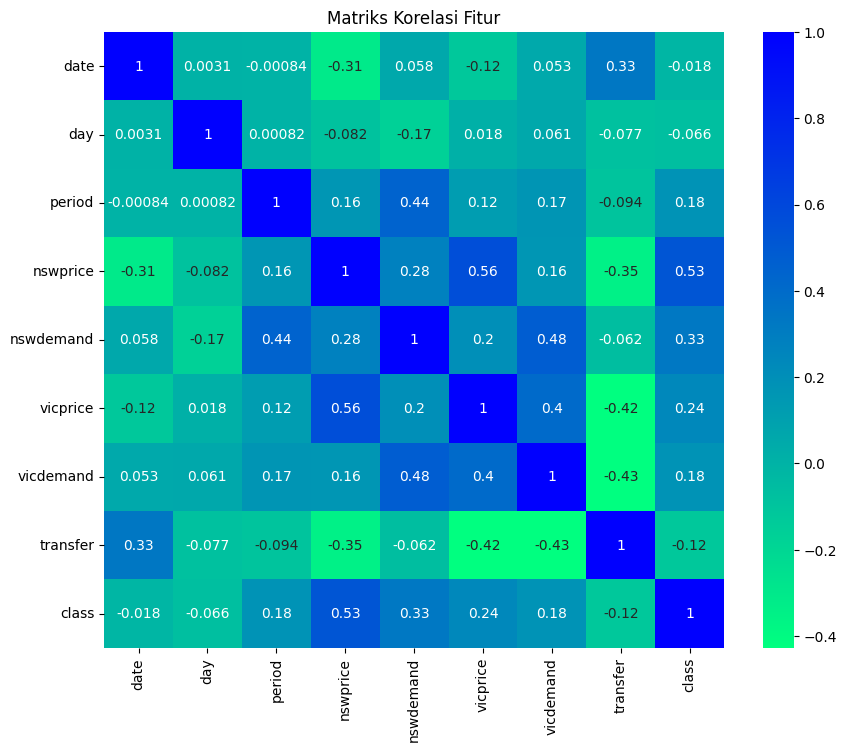

In [ ]:
# Plot matriks korelasi

plt.figure(figsize = (10, 8))
sns.heatmap(corr, annot = True, cmap = 'winter_r', cbar = True)
plt.title('Matriks Korelasi Fitur')
plt.show()


In [ ]:
cor_target = abs(corr['class'])
cor_features = cor_target[cor_target > 0.3]

# set fitur dengan korelasi yang tinggi
data_features = [index for index, value in cor_features.items()]
data_features.remove('class')

# manampilkan fitur-fitur yang berkolerasi dengan target
print(data_features)


['nswprice', 'nswdemand']


## **IMPLEMENTASI SVM**

---

In [ ]:
X = df[data_features].values
Y = df['class']


### **Scale the Data**

Alasan penting mengapa perlu dilakukan scaling pada data set terkait:
1. Perbedaan skala antar fitur → price dan demand kemungkinan punya rentang nilai yang berbeda-beda
2. Efektivitas SVM dalam pemisahan kelas.
3. Mengurangi bias pada fitur dengan rentang yang sangat besar.

In [ ]:
def scale_feature(X):
    mean = np.mean(X, axis = 0)
    std = np.std(X, axis = 0)

    # standardize the data
    X_scaled = (X - mean) / std
    return X_scaled


In [ ]:
X = scale_feature(X)


### **Split Data Training and Testing**

In [ ]:
def train_test_split(X, Y, random_state = 42, test_size = 0.2):
    #Ambil jummlah sample
    n_samples = X.shape[0]

    #Ambil seed untuk geneator angka random
    np.random.seed(random_state)

    #Shuffle indices
    shuffled_indices = np.random.permutation(np.arange(n_samples))

    #Menentukan ukuran test set
    test_size = int(test_size * n_samples)

    #Split data training dan testing
    test_indices = shuffled_indices[:test_size]
    train_indices = shuffled_indices[test_size:]

    #Split fitur dan target array menjadi testing dan tranining set
    X_train, X_test = X[train_indices], X[test_indices]
    Y_train, Y_test = Y.iloc[train_indices], Y.iloc[test_indices]

    return X_train, X_test, Y_train, Y_test


In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)
X_train.shape, X_test.shape


((19639, 2), (4909, 2))

### **Implementasi SVM**

In [ ]:
class SVM:

    # funsgi inisialisasi hyperparameter
    def __init__(self, iters = 1000, eta = 0.01, lambdaP = 0.01):
        self.iters = iters
        self.eta = eta
        self.lambdaP = lambdaP
        self.w = None
        self.b = None


    # fungsi fit untuk melatih model
    def fit(self, X, Y):
        # m = jumlah data-points (baris), n = jumlah fitur (kolom)
        m, n = X.shape

        #inisialisasi nilai bobot dan parameter bias
        self.w = np.zeros(n)
        self.b = 0
        self.X = X
        self.Y = Y

        for i in range(self.iters):
            self.update_parameters()


    # fungsi pembaharuan parameter
    def update_parameters(self):
        y_label = np.where(self.Y <= 0, -1, 1)

        # parameter gradient
        for i, x_i in enumerate(self.X):
            if (y_label[i] * (np.dot(x_i, self.w) - self.b)) >= 1:
                dw = 2 * self.lambdaP * self.w
                db = 0
            else:
                dw = 2 * self.lambdaP * self.w - np.dot(x_i, y_label[i])
                db = y_label[i]

            # update parameter
            self.w = self.w - self.eta * dw
            self.b = self.b - self.eta * db


    # fungsi prediksi data
    def prediksi(self, X):
        output = np.dot(X, self.w) - self.b

        # tambahakan tandah pada label jika lebih besar.kurang dari nol (0)
        predict_labels = np.sign(output)

        # tetapkan prediksi menjadi 0 jika kurang atau sama dengan -1, dan 1 untuk lainnya
        predict_final = np.where(predict_labels <= -1, 0, 1)

        return predict_final


### **Akurasi training data-testing data**

In [ ]:
def akurasi(Y_true, Y_pred):
    return np.sum(Y_true == Y_pred) / len(Y_true)

def presisi(Y_true, Y_pred):
    true_positive = np.sum((Y_true == 1) & (Y_pred == 1))
    predicted_positive = np.sum(Y_pred == 1)
    return true_positive / predicted_positive if predicted_positive > 0 else 0

def recall(Y_true, Y_pred):
    true_positive = np.sum((Y_true == 1) & (Y_pred == 1))
    actual_positive = np.sum(Y_true == 1)
    return true_positive / actual_positive if actual_positive > 0 else 0

def f1_score(Y_true, Y_pred):
    p = presisi(Y_true, Y_pred)
    r = recall(Y_true, Y_pred)
    return 2 * (p * r) / (p + r) if (p + r) > 0 else 0


In [ ]:
# inisiasi model dan lakukan fitting
model = SVM(iters=1000, eta=0.01, lambdaP=0.01)
model.fit(X_train, Y_train)

# perhitungan prediksi pada data training dan testing
predictionS_train = model.prediksi(X_train)
predictionS_test = model.prediksi(X_test)

# evaluasi testing data
print("Akurasi testing data = ", akurasi(Y_test, predictionS_test))
print("Presisi testing data = ", presisi(Y_test, predictionS_test))
print("Recall testing data = ", recall(Y_test, predictionS_test))
print("F1-Score testing data = ", f1_score(Y_test, predictionS_test))


Akurasi testing data =  0.7916072519861479
Presisi testing data =  0.7969264544456641
Recall testing data =  0.6897862232779097
F1-Score testing data =  0.7394957983193278
